In [5]:
import control as ctrl
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

In [6]:
# Transfer Functions

# 6/(s+1)(s+2)(s+3)
G1 = ctrl.TransferFunction([6], [1, 6, 11, 6])

# 2(s+2)/s^3 - 3s^2 + 2s + 4
G2 = ctrl.TransferFunction([2, 4], [1, -3, 2, 4])

# 1/s^4 + 5s^3 + 2s^2 - 7s + 1
G3 = ctrl.TransferFunction([1], [1, 5, 2, -7, 1])

# 12(s+2)/(s-1)(s-2)(s+3)(s+4)
G4 = ctrl.TransferFunction([12, 24], [1, 4, -7, -22, 24])

# 120/(s+1)(s+2)(s+3)(s+4)(s+5)
G5 = ctrl.TransferFunction(
    [120],
    [1, 15, 85, 225, 274, 120]
)

# 720/(s+1)(s+2)(s+3)(s+4)(s+5)(s+6)
G6 = ctrl.TransferFunction(
    [720],
    [1, 21, 175, 735, 1624, 1764, 720]
)

# Fix Kd
Kd = 0.5
systems = {
    "-6/(s+1)(s-2)(s+3)": G1,
    "2(s+2)/s^3 - 3s^2 + 2s + 4": G2,
    "1/s^4 + 5s^3 + 2s^2 - 7s + 1": G3,
    "12(s+2)/(s-1)(s-2)(s+3)(s+4)": G4,
    "120/(s+1)(s+2)(s+3)(s+4)(s+5)": G5,
    "720/(s+1)(s+2)(s+3)(s+4)(s+5)(s+6)": G6
}


In [7]:
# PID controller: Kd*s^2 + Kp*s + Ki, divided by s

import numpy as np
import control as ctrl

def is_stable(Kp, Ki, Kd, plant, eps=0.01):
    controller = ctrl.TransferFunction(
        [Kd, Kp, Ki], [1, 0]
    )

    closed_loop = ctrl.feedback(controller * plant, 1)

    # Simulate the closed-loop unit-step response
    t = np.linspace(0, 300, 300)

    try:
        response = ctrl.step_response(closed_loop, T=t)
        y = np.asarray(response.outputs).squeeze()

        if not np.all(np.isfinite(y)):
            return False

        # Reject responses that grow excessively
        if np.max(np.abs(y)) > 10:
            return False

        final_value = y[-1]

        # Overshoot relative to the final value
        if abs(final_value) < 1e-8:
            overshoot = np.inf
        else:
            overshoot = max(
                0.0,
                (np.max(y) - final_value) / abs(final_value) * 100
            )

        # Settling criterion: output remains within 1% of final value
        tolerance = max(eps * abs(final_value), eps)
        outside = np.where(np.abs(y - final_value) > tolerance)[0]

        if len(outside) == 0:
            settling_time = 0.0
        elif outside[-1] == len(t) - 1:
            settling_time = np.inf
        else:
            settling_time = t[outside[-1] + 1]

        return (overshoot < 10) and (settling_time < 300)

    except (ValueError, RuntimeError, TypeError, np.linalg.LinAlgError):
        return False

        


In [8]:

def trace_ray(theta, plant, Kd, max_t=14.2, scan_steps=300):
    """
    Return all sampled points along a ray, classified as stable or unstable.
    """

    def gains(t):
        return t * np.cos(theta), t * np.sin(theta)

    t_values = np.linspace(0.0, max_t, scan_steps + 1)

    stable_points = []
    unstable_points = []

    for t in t_values:
        Kp, Ki = gains(t)

        if is_stable(Kp, Ki, Kd, plant):
            stable_points.append((Kp, Ki))
        else:
            unstable_points.append((Kp, Ki))

    return stable_points, unstable_points


Processing -6/(s+1)(s-2)(s+3)...


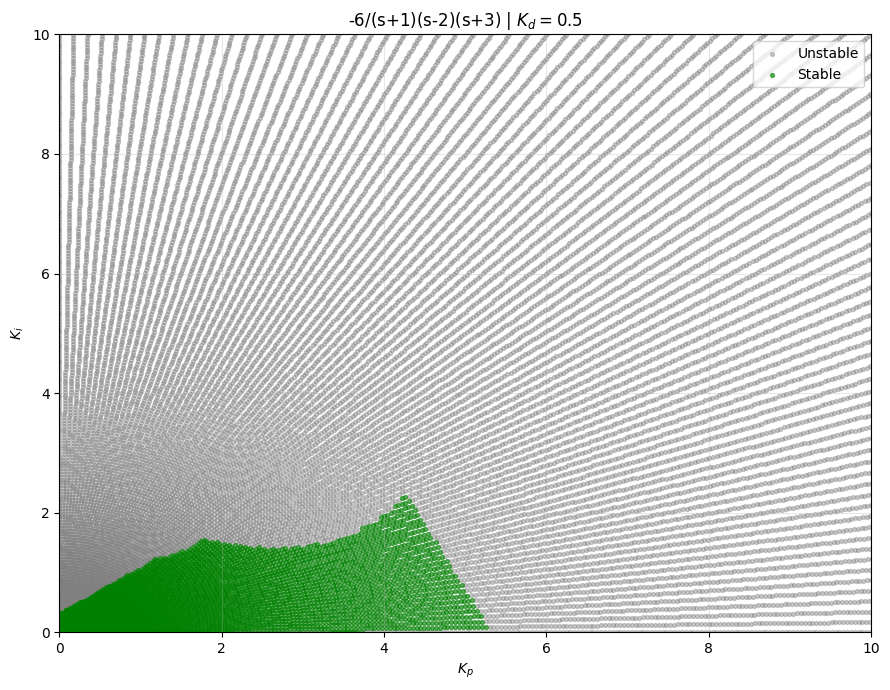

Processing 2(s+2)/s^3 - 3s^2 + 2s + 4...


C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\control\timeresp.py:1198: RuntimeWarning: overflow encountered in matmul
  yout = C @ xout + D @ U
C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\control\timeresp.py:1196: RuntimeWarning: overflow encountered in matmul
  xout[:, i] = (Ad @ xout[:, i-1]
C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\control\timeresp.py:1196: RuntimeWarning: invalid value encountered in matmul
  xout[:, i] = (Ad @ xout[:, i-1]
C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\control\timeresp.py:1198: RuntimeWarning: invalid value encountered in matmul
  yout = C @ xout + D @ U


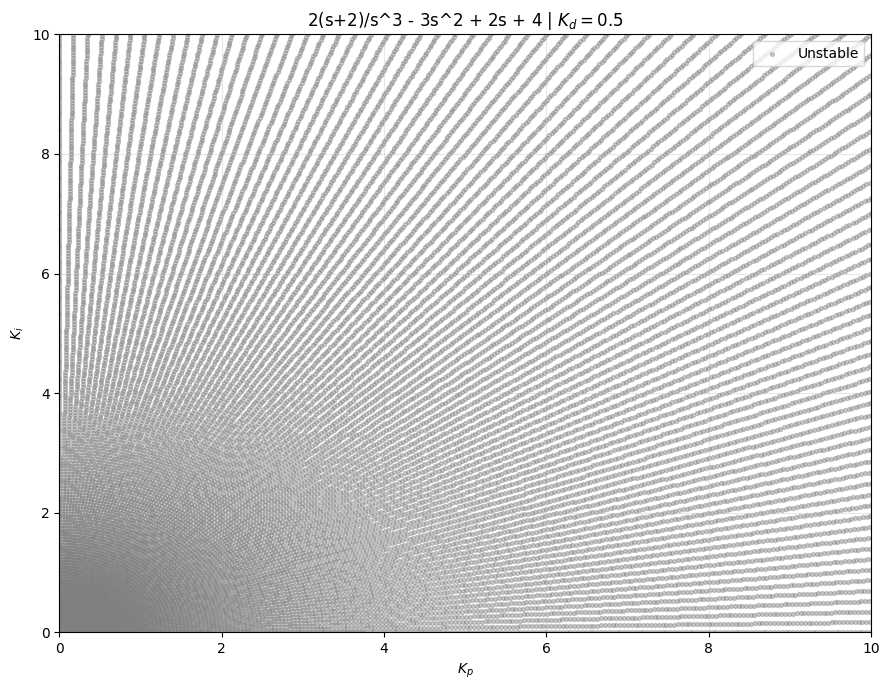

Processing 1/s^4 + 5s^3 + 2s^2 - 7s + 1...


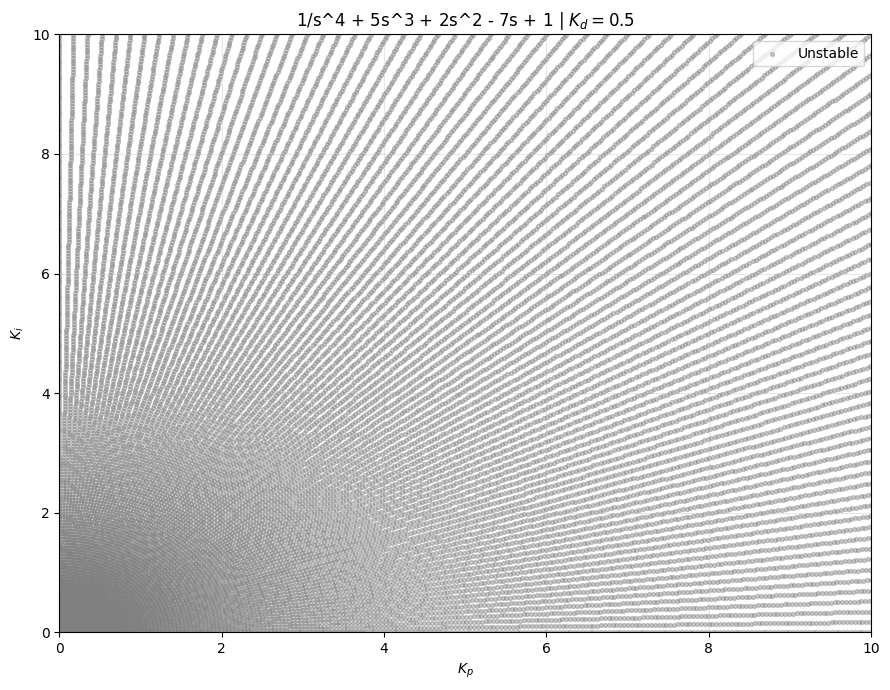

Processing 12(s+2)/(s-1)(s-2)(s+3)(s+4)...


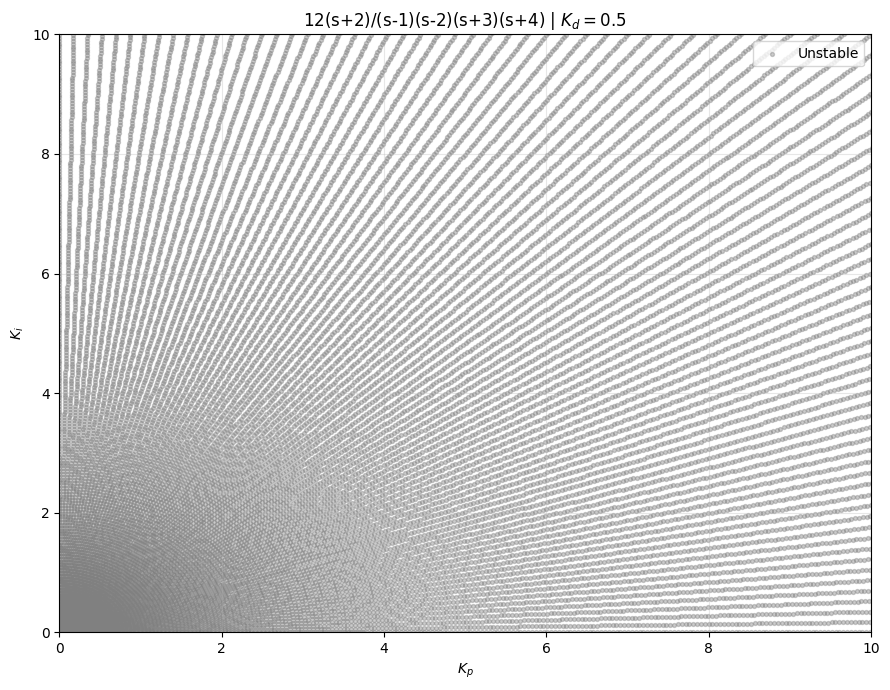

Processing 120/(s+1)(s+2)(s+3)(s+4)(s+5)...


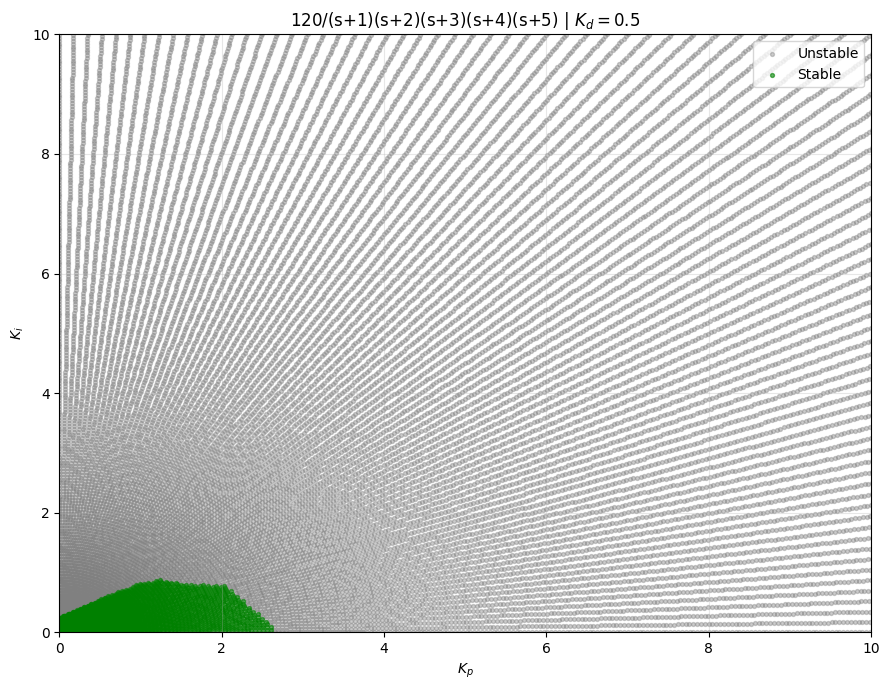

Processing 720/(s+1)(s+2)(s+3)(s+4)(s+5)(s+6)...


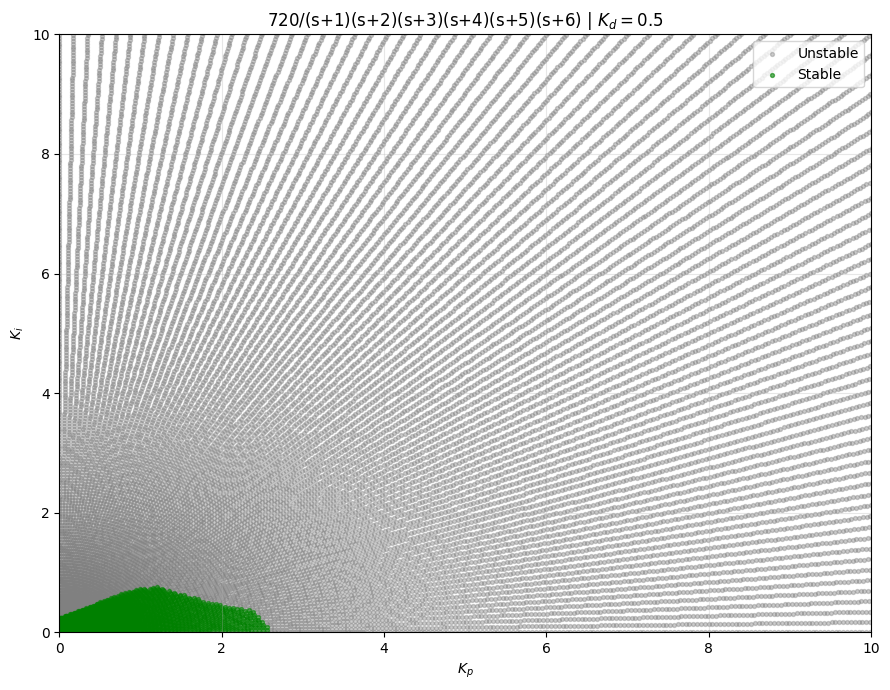

In [9]:
# Stability map settings
Kp_grid = np.linspace(0, 20, 100)
Ki_grid = np.linspace(0, 20, 100)


angles_deg = np.linspace(0, 90, 91)

for system_name, plant in systems.items():
    print(f"Processing {system_name}...")

    all_stable = []
    all_unstable = []

    for angle_deg in angles_deg:
        stable, unstable = trace_ray(
            theta=np.deg2rad(angle_deg),
            plant=plant,
            Kd=Kd,
            max_t=14.2,
            scan_steps=300
        )

        all_stable.extend(stable)
        all_unstable.extend(unstable)

    all_stable = np.asarray(all_stable).reshape(-1, 2)
    all_unstable = np.asarray(all_unstable).reshape(-1, 2)

    plt.figure(figsize=(9, 7))

    if len(all_unstable) > 0:
        plt.scatter(
            all_unstable[:, 0], all_unstable[:, 1],
            color="grey", s=8, alpha=0.4,
            label="Unstable"
        )

    if len(all_stable) > 0:
        plt.scatter(
            all_stable[:, 0], all_stable[:, 1],
            color="green", s=8, alpha=0.6,
            label="Stable"
        )

    plt.xlabel("$K_p$")
    plt.ylabel("$K_i$")
    plt.title(f"{system_name} | $K_d={Kd}$")
    plt.xlim(0, 10)
    plt.ylim(0, 10)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
